# Checkpoint pipeline — QPINN vs. classical PINN

One notebook for both headline experiments, run from checkpoints so training
never has to be repeated just to change a plot:

1. **Parameter sweep** — fix architecture size `L`, sweep `(freq, alpha)` (heat)
   or `(freq, c)` (wave), classical vs. quantum, heatmap of `rel_l2`.
2. **L sweep** — fix `(freq, alpha)`/`(freq, c)`, sweep `L`, classical vs.
   quantum, line plot of `rel_l2` vs. `L`.

Both experiments share ONE notion of "model size `L`": the quantum model is
`MerlinTunableEntropy(n_encoding_layers=L)`, matched at every `L` to a
`ClassicalHeatQPINN` with (as close as brute-force search gets) the same
trainable parameter count.

**How the checkpoint mechanism works** (see `src/checkpoints.py` for the
full docstrings):

- Every single `(pde params, L, model_type, seed)` run is trained once and
  saved as its own file under `checkpoints/<experiment>/`, containing
  everything needed to replot it later: weights, loss history, the
  evaluation grid, metrics, diagnostics.
- Re-running a "run cell" below with the SAME config **skips** any run
  already on disk — only genuinely new runs (new seed, new grid point, new
  `L`, ...) train. This is what lets you add seeds progressively.
- All "plot" cells below only ever `load_checkpoints(...)` from disk — they
  never retrain anything. Edit a plotting function in
  `src/checkpoint_plots.py` and just re-run the plot cell to see the new
  version, no matter how long the runs took originally.
- To increase statistics later: bump `seeds=(...)` in a run cell and
  re-run it, then re-run the corresponding plot cell.


In [1]:
%load_ext autoreload
%autoreload 2

import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent  # running from notebooks/
sys.path.insert(0, str(ROOT))

import torch
from src.pde import HeatEquation, WaveEquation
from src.checkpoints import (
    run_param_sweep_checkpoints, run_L_sweep_checkpoints, resume_checkpoint,
    load_checkpoint, load_checkpoints, checkpoints_to_dataframe, resolve_matched_config,
    run_param_sweep_ff_checkpoints, run_L_sweep_ff_checkpoints,
)
from src.checkpoint_plots import (
    plot_param_sweep_heatmap, plot_L_sweep,
    plot_checkpoint_training_curve, plot_checkpoint_solution, plot_checkpoint_spectrum,
    plot_effective_bandwidth_vs_L,
    plot_ff_control_heatmap, plot_L_sweep_with_ff,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

# Shared across both experiments: matching search results get cached here so
# re-running a cell (or running the other experiment at the same L) never
# repeats the brute-force classical-parameter search.
MATCH_CACHE = {}


device: cpu


## Shared architecture config

Pick the quantum layer's `feature_size` / `hidden_feature` / `hidden_readout`
once here — both experiments below build on top of it. `L` itself is fixed
for experiment 1 and swept in experiment 2.

In [2]:
FEATURE_SIZE = 4          # quantum input modes - 1
HIDDEN_FEATURE = 16       # feature_map hidden width
HIDDEN_READOUT_QUANTUM = 4  # quantum model's readout hidden width

PDE_TYPE = "heat"         # "heat" | "wave"

EPOCHS = 15000
TRACK_BEST = True         # evaluate on a fixed grid periodically, keep the best checkpoint
EVAL_EVERY = 200
SEEDS = [42, 666, 69, 67]#(42, 666, 69, 67)


---
## Experiment 1 — parameter sweep at fixed L

Sweep `(freq, alpha)` (heat) / `(freq, c)` (wave) at a fixed architecture
size `L`, classical vs. quantum, for every seed in `SEEDS`.

In [3]:
L_PARAM_SWEEP = 1

FREQ_VALUES = [0.5, 1.0]#[0.5, 1.5, 2.5, 3.5]
ALPHA_OR_C_VALUES = [0.025]#[0.01, 0.05, 0.1, 0.25]   # alpha for heat, c for wave
PARAM2_NAME = "alpha" if PDE_TYPE == "heat" else "c"

PARAM_SWEEP_DIR = ROOT / "checkpoints" / "param_sweep"


In [26]:
# Trains only whatever isn't already on disk for this exact config -- safe
# to re-run after editing SEEDS/FREQ_VALUES/ALPHA_OR_C_VALUES to extend the
# sweep; already-done runs are skipped.
run_param_sweep_checkpoints(
    ckpt_dir=PARAM_SWEEP_DIR,
    pde_type=PDE_TYPE,
    param1_name="freq", param1_values=FREQ_VALUES,
    param2_name=PARAM2_NAME, param2_values=ALPHA_OR_C_VALUES,
    L=L_PARAM_SWEEP,
    feature_size=FEATURE_SIZE, hidden_feature=HIDDEN_FEATURE,
    hidden_readout_quantum=HIDDEN_READOUT_QUANTUM,
    seeds=SEEDS, epochs=EPOCHS, device=DEVICE,
    track_best=TRACK_BEST, eval_every=EVAL_EVERY,
    match_cache=MATCH_CACHE,
)


[checkpoints] L=1: quantum_params=310  bound=±3  classical match -> quantum_output_size=6 hidden_readout=18 params=310 (diff=+0)
Parameters — total: 310  trainable: 310

Training for 15000 epochs on cpu  (dtype=torch.float32)
Epoch     1/15000 | Loss: 2.0250e+00 | PDE: 3.65e-04 | Cons: 3.10e-02 | IC: 4.02e-01 | BC: 0.00e+00 | Time: 0.0s
Evaluating on 60×60 grid …
  Relative L2 : 8.7295e-01
  MAE         : 4.8269e-01
  Max abs err : 8.9377e-01
  RMSE        : 5.4390e-01
Epoch    50/15000 | Loss: 5.1610e-01 | PDE: 6.71e-02 | Cons: 4.26e-01 | IC: 4.72e-02 | BC: 0.00e+00 | Time: 0.1s
Epoch   100/15000 | Loss: 1.5987e-02 | PDE: 7.23e-03 | Cons: 1.64e-02 | IC: 1.14e-04 | BC: 0.00e+00 | Time: 0.2s
Epoch   150/15000 | Loss: 6.7911e-03 | PDE: 3.08e-03 | Cons: 6.41e-03 | IC: 1.01e-04 | BC: 0.00e+00 | Time: 0.3s
Epoch   200/15000 | Loss: 4.4049e-03 | PDE: 2.39e-03 | Cons: 3.55e-03 | IC: 4.81e-05 | BC: 0.00e+00 | Time: 0.4s
Evaluating on 60×60 grid …
  Relative L2 : 1.7887e-02
  MAE         : 8.37

KeyboardInterrupt: 

4 checkpoints loaded
Saved: /Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/figures/checkpoint_pipeline/param_sweep_heatmap.png


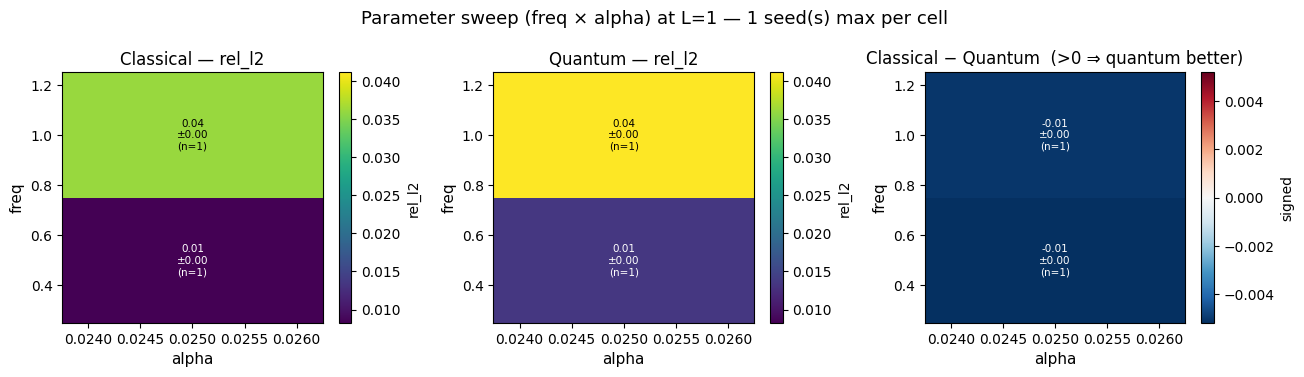

In [11]:
# Plotting only ever reads from disk -- rerun this cell any time (e.g. after
# editing plot_param_sweep_heatmap) without retraining anything.
param_sweep_ckpts = load_checkpoints(PARAM_SWEEP_DIR, pde_type=PDE_TYPE, L=L_PARAM_SWEEP)
print(f"{len(param_sweep_ckpts)} checkpoints loaded")

fig = plot_param_sweep_heatmap(
    param_sweep_ckpts, param1_name="freq", param2_name=PARAM2_NAME,
    metric="rel_l2", save_path=ROOT / "figures" / "checkpoint_pipeline" / "param_sweep_heatmap.png",
)


In [9]:
# Quick table view of every run in this experiment -- sort/filter as needed.
checkpoints_to_dataframe(param_sweep_ckpts).sort_values(["freq", PARAM2_NAME, "model_type", "seed"])


,schema_version,pde_type,model_type,L,feature_size,hidden_feature,hidden_readout,quantum_output_size,seed,epochs,...,alpha,rel_l2,mae,max_abs_error,rmse,eval_epoch,param_count,analytic_bound,diag_passed,path
0,1,heat,classical,1,4,16,18,6.0,42,600,...,0.025,0.008270,0.004057,0.015422,0.005153,600,310,NaN,True,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
1,1,heat,quantum,1,4,16,4,NaN,42,600,...,0.025,0.013442,0.006860,0.019104,0.008375,600,310,3.0,True,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
2,1,heat,classical,1,4,16,18,6.0,42,600,...,0.025,0.036072,0.012568,0.060106,0.016749,600,310,NaN,True,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
3,1,heat,quantum,1,4,16,4,NaN,42,600,...,0.025,0.041110,0.014036,0.080687,0.019088,600,310,3.0,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...


---
## Experiment 2 — L sweep at fixed PDE parameters

Fix `(freq, alpha)`/`(freq, c)`, sweep architecture size `L`, classical vs.
quantum, for every seed in `SEEDS`.

In [4]:
DEPTHS = [1, 2, 3, 4]
#DEPTHS = [5]

FIXED_FREQ = 5.0
FIXED_ALPHA_OR_C = 0.0025

if PDE_TYPE == "heat":
    L_SWEEP_PDE = HeatEquation(freq=FIXED_FREQ, alpha=FIXED_ALPHA_OR_C)
else:
    L_SWEEP_PDE = WaveEquation(freq=FIXED_FREQ, c=FIXED_ALPHA_OR_C)

L_SWEEP_DIR = ROOT / "checkpoints" / "L_sweep"


In [77]:
run_L_sweep_checkpoints(
    ckpt_dir=L_SWEEP_DIR,
    pde=L_SWEEP_PDE,
    depths=DEPTHS,
    feature_size=FEATURE_SIZE, hidden_feature=HIDDEN_FEATURE,
    hidden_readout_quantum=HIDDEN_READOUT_QUANTUM,
    seeds=SEEDS, epochs=EPOCHS, device=DEVICE,
    track_best=TRACK_BEST, eval_every=EVAL_EVERY,
    match_cache=MATCH_CACHE,
)


[checkpoints] L=5: quantum_params=662  bound=±15  classical match -> quantum_output_size=10 hidden_readout=38 params=662 (diff=+0)
Parameters — total: 662  trainable: 662

Training for 15000 epochs on cpu  (dtype=torch.float32)
Epoch     1/15000 | Loss: 2.7086e+00 | PDE: 6.08e-06 | Cons: 8.73e-03 | IC: 5.41e-01 | BC: 0.00e+00 | Time: 0.0s
Evaluating on 60×60 grid …
  Relative L2 : 1.0010e+00
  MAE         : 1.3277e-01
  Max abs err : 1.0083e+00
  RMSE        : 2.3303e-01
Epoch    50/15000 | Loss: 2.3830e+00 | PDE: 7.93e-08 | Cons: 1.06e-03 | IC: 4.76e-01 | BC: 0.00e+00 | Time: 0.1s
Epoch   100/15000 | Loss: 2.6189e+00 | PDE: 7.38e-07 | Cons: 8.13e-04 | IC: 5.24e-01 | BC: 0.00e+00 | Time: 0.2s
Epoch   150/15000 | Loss: 2.2632e+00 | PDE: 1.38e-07 | Cons: 4.45e-03 | IC: 4.52e-01 | BC: 0.00e+00 | Time: 0.3s
Epoch   200/15000 | Loss: 2.5738e+00 | PDE: 1.07e-06 | Cons: 2.65e-03 | IC: 5.14e-01 | BC: 0.00e+00 | Time: 0.4s
Evaluating on 60×60 grid …
  Relative L2 : 1.0022e+00
  MAE         : 1.

[PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p0025_freq7__L5__fs4_hf16_hr38_qos10__classical__seed42__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p0025_freq7__L5__fs4_hf16_hr4__quantum__seed42__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p0025_freq7__L5__fs4_hf16_hr38_qos10__classical__seed666__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p0025_freq7__L5__fs4_hf16_hr4__quantum__seed666__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p0025_freq7__L5__fs4_hf16_hr38_qos10__classical__seed69__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p0025_freq7__L5__fs4_hf16_hr4__quantum__seed69__ep15000.pt'),
 PosixPath('/Users/hono

52 checkpoints loaded
Saved: /Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/figures/checkpoint_pipeline/L_sweep.png


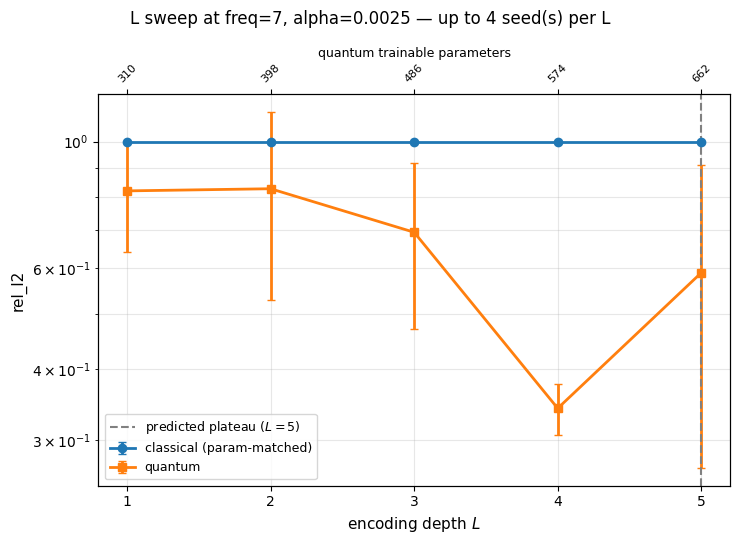

In [78]:
L_sweep_ckpts = load_checkpoints(
    L_SWEEP_DIR, pde_type=PDE_TYPE, freq=FIXED_FREQ, **{PARAM2_NAME: FIXED_ALPHA_OR_C},
)
print(f"{len(L_sweep_ckpts)} checkpoints loaded")

# target_frequency: the PDE's integer spatial mode (2*freq for the heat
# convention used elsewhere in this repo) -- marks the theory's predicted
# plateau point (L * n_photons >= target_frequency).
fig = plot_L_sweep(
    L_sweep_ckpts, metric="rel_l2", target_frequency=2 * FIXED_FREQ,
    save_path=ROOT / "figures" / "checkpoint_pipeline" / "L_sweep.png",
)


In [30]:
checkpoints_to_dataframe(L_sweep_ckpts).sort_values(["L", "model_type", "seed"])


,schema_version,pde_type,model_type,L,feature_size,hidden_feature,hidden_readout,quantum_output_size,seed,epochs,...,alpha,rel_l2,mae,max_abs_error,rmse,eval_epoch,param_count,analytic_bound,diag_passed,path
0,1,heat,classical,1,4,16,18,6.0,42,15000,...,0.0025,0.999998,0.233964,0.999642,0.318513,3400,310,NaN,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
1,1,heat,quantum,1,4,16,4,NaN,42,15000,...,0.0025,0.115706,0.025430,0.274990,0.036854,14800,310,3.0,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
3,1,heat,classical,2,4,16,54,2.0,42,15000,...,0.0025,0.999997,0.233964,0.999564,0.318512,3400,398,NaN,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
2,1,heat,quantum,2,4,16,4,NaN,42,15000,...,0.0025,0.215394,0.041144,0.464039,0.068606,14800,398,6.0,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
5,1,heat,classical,3,4,16,59,3.0,42,15000,...,0.0025,1.000000,0.233963,0.999667,0.318513,1200,487,NaN,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
4,1,heat,quantum,3,4,16,4,NaN,42,15000,...,0.0025,0.129260,0.029344,0.257580,0.041171,14800,486,9.0,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
7,1,heat,classical,4,4,16,54,5.0,42,15000,...,0.0025,1.000000,0.233963,0.999676,0.318513,3200,575,NaN,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
6,1,heat,quantum,4,4,16,4,NaN,42,15000,...,0.0025,0.138459,0.032165,0.262903,0.044101,14800,574,12.0,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...


---
## Per-checkpoint plots — training curve, spectral content, learnt vs. exact solution

Pick any single run from either experiment above (by its row in the
dataframe / its config) and inspect it directly, with no retraining. Spectral
content only applies to `model_type="quantum"` checkpoints (classical models
have no quantum layer).

In [87]:
# Example: the quantum run with the largest error in the L sweep -- swap in
# any (dir, filters) you want to look at.
df = checkpoints_to_dataframe(L_sweep_ckpts)
worst = df[df.model_type == "quantum"].sort_values("rel_l2", ascending=False).iloc[0]
print(worst)

ckpt = load_checkpoints(
    L_SWEEP_DIR, 
    model_type="quantum", 
    L=5,               #L=int(worst.L), 
    seed = 69,       #seed=int(worst.seed),
    freq=FIXED_FREQ, 
    **{PARAM2_NAME: FIXED_ALPHA_OR_C},
)[0]


schema_version                                                         1
pde_type                                                            heat
model_type                                                       quantum
L                                                                      2
feature_size                                                           4
hidden_feature                                                        16
hidden_readout                                                         4
quantum_output_size                                                  NaN
seed                                                                 666
epochs                                                             15000
track_best                                                          True
eval_every                                                           200
eval_nx                                                               60
eval_nt                                            

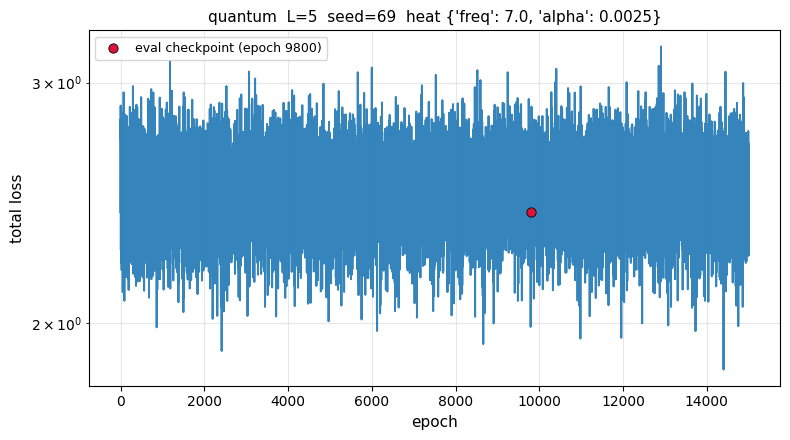

In [88]:
_ = plot_checkpoint_training_curve(ckpt, component="total")


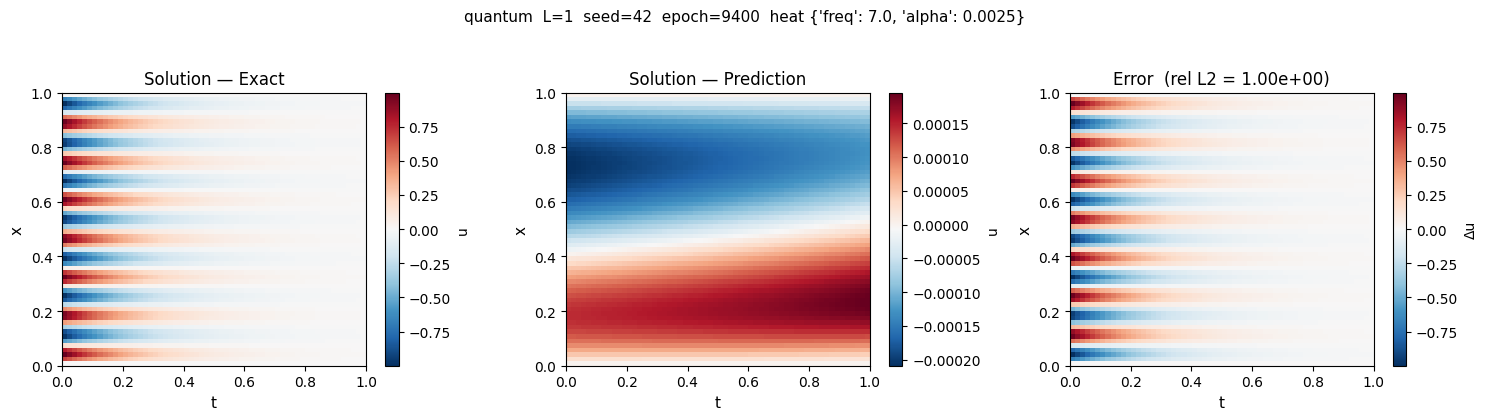

In [37]:
_ = plot_checkpoint_solution(ckpt)


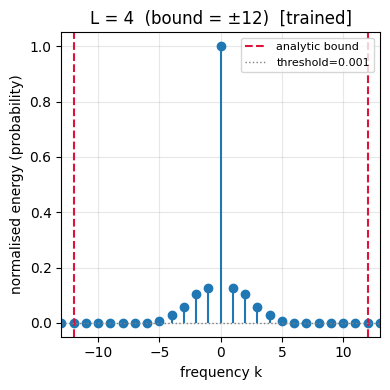

In [50]:
_ = plot_checkpoint_spectrum(ckpt)  # quantum-only

---
## Spectral bandwidth vs. encoding depth

Reduces every QUANTUM checkpoint's quantum-layer spectrum (the same
`quantum_layer_spectrum` used in the per-checkpoint spectrum plot above) to
a single scalar per run, then plots that scalar as a function of `L`, mean
± std over however many seeds are present at each `L` — built directly from
`L_sweep_ckpts`, so this combines incrementally the same way `plot_L_sweep`
does (rerun after adding seeds, no retraining needed). The dashed line is
the analytic ceiling `\Omega = L \cdot n_photons` from each checkpoint's
stored `analytic_bound`.

Swap `metric` for `"spectral_second_moment"` (energy-weighted RMS, no
threshold) or `"fraction_of_ceiling_used"` (bounded in [0, 1], directly
comparable across `L`) — see `src/checkpoint_plots.py::_SPECTRUM_METRICS`.

Saved: /Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/figures/checkpoint_pipeline/effective_bandwidth_vs_L.png


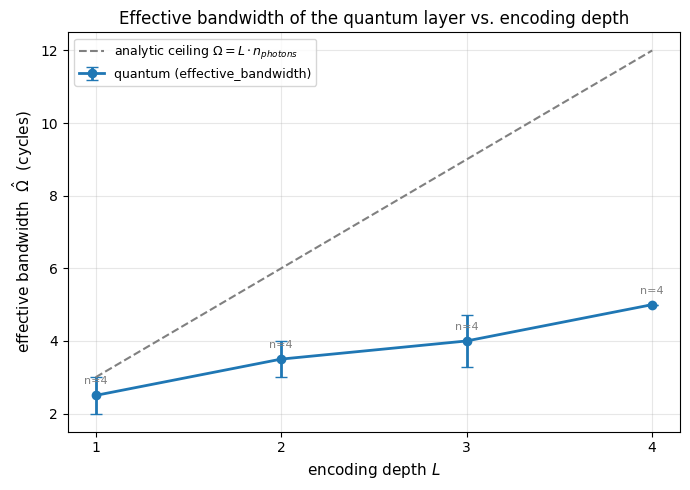

,L,seed,value,analytic_bound
0,1,42,2.0,3
2,1,67,3.0,3
3,1,69,3.0,3
1,1,666,2.0,3
4,2,42,3.0,6
6,2,67,4.0,6
7,2,69,3.0,6
5,2,666,4.0,6
8,3,42,4.0,9
10,3,67,5.0,9


In [55]:
fig, bandwidth_df = plot_effective_bandwidth_vs_L(
    L_sweep_ckpts, metric="effective_bandwidth",
    save_path=ROOT / "figures" / "checkpoint_pipeline" / "effective_bandwidth_vs_L.png",
)
bandwidth_df.sort_values(["L", "seed"])

---

## Resuming — continue training an existing checkpoint

`resume_checkpoint` takes any checkpoint (a loaded dict or a path), trains
it for a few hundred more epochs, and saves the result as a NEW file (same
config, `epochs` bumped, plus a `resumed_from_epochs` field) — the original
file is untouched. This is a lightweight resume (fresh optimizer state,
reseeded sampling for the extra epochs), not bit-exact continuation; see
`resume_checkpoint`'s docstring for why that's fine here.

Sanity-checking it on the `ckpt` picked out above: rel_l2 should improve (or
at least not get meaningfully worse), the epoch count should grow by exactly
`additional_epochs`, and the training curve should show the original run's
history followed seamlessly by the new epochs, with a marker at the
combined run's actual eval checkpoint.

In [24]:
print(f"before resume: epochs={ckpt['config']['epochs']}  rel_l2={ckpt['metrics']['rel_l2']:.3e}")

resumed_path = resume_checkpoint(
    ckpt_dir=L_SWEEP_DIR,
    source=ckpt,
    additional_epochs=200,
    device=DEVICE,
    track_best=TRACK_BEST, eval_every=EVAL_EVERY,
)
resumed_ckpt = load_checkpoint(resumed_path)

print(f"after resume:  epochs={resumed_ckpt['config']['epochs']}  rel_l2={resumed_ckpt['metrics']['rel_l2']:.3e}")
assert resumed_ckpt["config"]["epochs"] == ckpt["config"]["epochs"] + 200
assert len(resumed_ckpt["history"]) == len(ckpt["history"]) + 200
print("OK -- resumed checkpoint has the expected epoch count and history length")


before resume: epochs=600  rel_l2=7.303e-01
Parameters — total: 310  trainable: 310

Training for 200 epochs on cpu  (dtype=torch.float32)
Epoch     1/200 | Loss: 1.6474e+00 | PDE: 7.99e-02 | Cons: 1.12e+00 | IC: 2.02e-01 | BC: 0.00e+00 | Time: 0.1s
Evaluating on 60×60 grid …
  Relative L2 : 8.0648e-01
  MAE         : 9.2906e-02
  Max abs err : 7.6553e-01
  RMSE        : 1.6807e-01
Evaluating on 60×60 grid …
  Relative L2 : 7.3128e-01
  MAE         : 8.4580e-02
  Max abs err : 6.9447e-01
  RMSE        : 1.5239e-01

Done — 18.6s total
[track_best] restoring epoch 200/200 weights (fixed-grid rel_l2=7.3128e-01) in place of the final epoch's weights (final-epoch fixed-grid rel_l2=7.3128e-01)
Evaluating on 60×60 grid …
  Relative L2 : 7.3128e-01
  MAE         : 8.4580e-02
  Max abs err : 6.9447e-01
  RMSE        : 1.5239e-01
[checkpoints] resumed /Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p025_freq2p5__L1__fs4_hf16_hr4__quantum__seed42__ep600.pt (600

---
## Experiment 3 — Fourier-features spectral-coverage control

Direct test of the paper's own spectral-coverage hypothesis (`sec:spectral`):
*"a purely classical map with the same [fixed] spectral support would do
just as well"* -- with NO quantum circuit at all. `FourierFeaturesHeatQPINN`
(see its docstring in `src/models.py`) replaces the quantum/classical middle
block with a FIXED (non-trainable) sinusoidal encoding at integer
frequencies `1..n_freqs` on each axis, `n_freqs = L * n_photons` -- exactly
the quantum arm's own analytic frequency ceiling at that `L`
(`analytic_frequency_bound`) -- followed by a STRICTLY LINEAR trainable
combination layer (deliberately no activation, so it can't manufacture
frequencies beyond `n_freqs` itself, which would defeat the point of the
control). Parameter count is matched to the quantum arm the same way the
classical arm is, via brute-force search (`resolve_matched_ff_config`).

Both cells below ADD a third arm (`model_type="fourier_features"`) to the
SAME checkpoint directories experiments 1 and 2 already wrote to -- they do
not retrain classical/quantum. Run experiments 1 and 2 above first.

**Reading the result:** if the fourier-features arm tracks the quantum arm
(matches its accuracy in the window / reproduces the widening-with-`L`
effect), that's strong support for "spectral coverage, not quantumness".
If it doesn't -- despite matching both frequency reach and parameter count
-- that points to the quantum layer's specific bilinear, unitarity-
constrained parameterisation doing something a fixed basis with free linear
coefficients can't reproduce.

In [4]:
# Control for Experiment 1: same (freq, alpha)/(freq, c) grid, same L, same
# seeds -- writes into PARAM_SWEEP_DIR alongside the classical/quantum runs.
run_param_sweep_ff_checkpoints(
    ckpt_dir=PARAM_SWEEP_DIR,
    pde_type=PDE_TYPE,
    param1_name="freq", param1_values=FREQ_VALUES,
    param2_name=PARAM2_NAME, param2_values=ALPHA_OR_C_VALUES,
    L=L_PARAM_SWEEP,
    feature_size=FEATURE_SIZE, hidden_feature=HIDDEN_FEATURE,
    hidden_readout_quantum=HIDDEN_READOUT_QUANTUM,
    seeds=SEEDS, epochs=EPOCHS, device=DEVICE,
    track_best=TRACK_BEST, eval_every=EVAL_EVERY,
    match_cache=MATCH_CACHE, verbose=True
)


[checkpoints] L=1: quantum_params=310  bound=±3 (n_freqs=3)  ff (architecture-matched) -> quantum_output_size=35 hidden_readout=4 params=226 (diff=-84)
Parameters — total: 226  trainable: 226

Training for 15000 epochs on cpu  (dtype=torch.float32)
Epoch     1/15000 | Loss: 3.2347e+00 | PDE: 4.65e-04 | Cons: 4.70e-01 | IC: 6.00e-01 | BC: 0.00e+00 | Time: 0.0s
Evaluating on 60×60 grid …
  Relative L2 : 1.1170e+00
  MAE         : 6.2086e-01
  Max abs err : 1.1036e+00
  RMSE        : 6.9594e-01
Epoch    50/15000 | Loss: 1.0315e+00 | PDE: 8.50e-02 | Cons: 4.85e-01 | IC: 1.41e-01 | BC: 0.00e+00 | Time: 0.1s
Epoch   100/15000 | Loss: 6.4046e-01 | PDE: 1.55e-01 | Cons: 5.68e-01 | IC: 4.03e-02 | BC: 0.00e+00 | Time: 0.2s
Epoch   150/15000 | Loss: 1.8612e-01 | PDE: 4.19e-02 | Cons: 1.42e-01 | IC: 1.47e-02 | BC: 0.00e+00 | Time: 0.3s
Epoch   200/15000 | Loss: 6.4400e-02 | PDE: 6.04e-03 | Cons: 6.16e-02 | IC: 5.51e-03 | BC: 0.00e+00 | Time: 0.5s
Evaluating on 60×60 grid …
  Relative L2 : 1.3378e-

[PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/param_sweep/heat__alpha0p025_freq0p5__L1__fs4_hf16_hr4_qos35__fourier_features__seed42__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/param_sweep/heat__alpha0p025_freq0p5__L1__fs4_hf16_hr4_qos35__fourier_features__seed666__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/param_sweep/heat__alpha0p025_freq0p5__L1__fs4_hf16_hr4_qos35__fourier_features__seed69__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/param_sweep/heat__alpha0p025_freq0p5__L1__fs4_hf16_hr4_qos35__fourier_features__seed67__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/param_sweep/heat__alpha0p025_freq1__L1__fs4_hf16_hr4_qos35__fourier_features__seed42__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/param_sweep/heat__alpha0p025_freq1_

10 checkpoints loaded
Saved: /Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/figures/checkpoint_pipeline/ff_control_heatmap.png


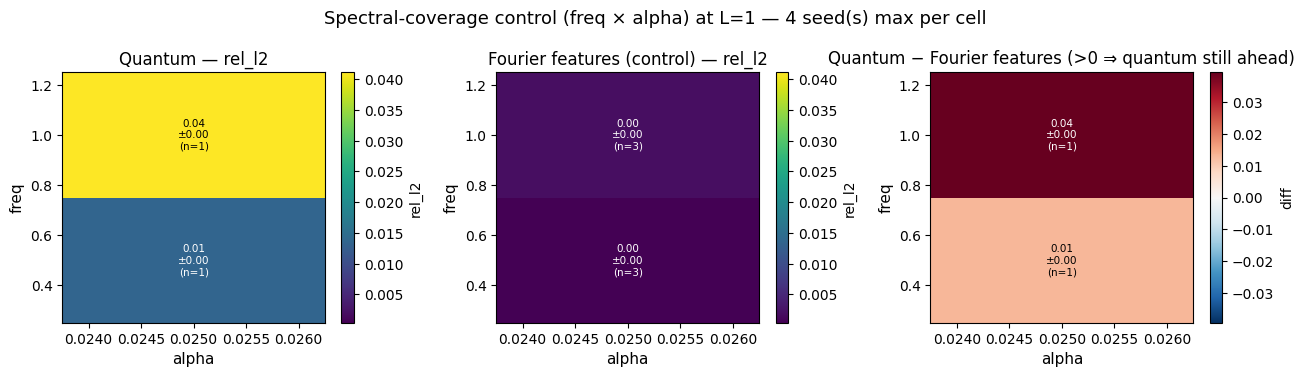

In [70]:
# Reload -- now picks up all three arms (classical, quantum, fourier_features).
param_sweep_ckpts = load_checkpoints(PARAM_SWEEP_DIR, pde_type=PDE_TYPE, L=L_PARAM_SWEEP)
print(f"{len(param_sweep_ckpts)} checkpoints loaded")

fig = plot_ff_control_heatmap(
    param_sweep_ckpts, param1_name="freq", param2_name=PARAM2_NAME,
    metric="rel_l2",
    save_path=ROOT / "figures" / "checkpoint_pipeline" / "ff_control_heatmap.png",
)

In [6]:
# Control for Experiment 2: same fixed (freq, alpha)/(freq, c), same depths,
# same seeds -- writes into L_SWEEP_DIR alongside the classical/quantum runs.
# n_freqs = L * n_photons is recomputed per L inside resolve_matched_ff_config,
# so this arm's frequency reach grows with L exactly like the quantum arm's.

#import glob, os
#removed = glob.glob(str(L_SWEEP_DIR / "*fourier_features*"))
#for f in removed:
    #os.remove(f)
#print(f"removed {len(removed)} stale fourier_features checkpoints")

#for mt in ('fourier_modulus'): #"fourier_full", "fourier_modulus", "fourier_features"
#    run_L_sweep_ff_checkpoints(
#        ckpt_dir=L_SWEEP_DIR, pde=L_SWEEP_PDE, depths=DEPTHS,
#        feature_size=FEATURE_SIZE, hidden_feature=HIDDEN_FEATURE,
#        hidden_readout_quantum=HIDDEN_READOUT_QUANTUM,
#        seeds=SEEDS, epochs=EPOCHS, device=DEVICE,
#        track_best=TRACK_BEST, eval_every=EVAL_EVERY,
#        model_type=mt, match_cache=MATCH_CACHE,
#    )
run_L_sweep_ff_checkpoints(
    ckpt_dir=L_SWEEP_DIR, pde=L_SWEEP_PDE, depths=DEPTHS,
    feature_size=FEATURE_SIZE, hidden_feature=HIDDEN_FEATURE,
    hidden_readout_quantum=HIDDEN_READOUT_QUANTUM,
    seeds=SEEDS, epochs=EPOCHS, device=DEVICE,
    track_best=TRACK_BEST, eval_every=EVAL_EVERY,
    model_type="fourier_unitary", match_cache=MATCH_CACHE,
)


[checkpoints] L=1: quantum_params=310  bound=±3 (n_freqs=3)  ff (architecture-matched) -> quantum_output_size=35 hidden_readout=4 params=935 (diff=+625)
Parameters — total: 935  trainable: 935

Training for 15000 epochs on cpu  (dtype=torch.float32)
Epoch     1/15000 | Loss: 2.5263e+00 | PDE: 4.12e-07 | Cons: 1.05e-01 | IC: 4.95e-01 | BC: 0.00e+00 | Time: 0.0s
Evaluating on 60×60 grid …
  Relative L2 : 1.0021e+00
  MAE         : 2.3414e-01
  Max abs err : 1.0125e+00
  RMSE        : 3.1917e-01
Evaluating on 60×60 grid …
  Relative L2 : 1.0004e+00
  MAE         : 2.3398e-01
  Max abs err : 1.0052e+00
  RMSE        : 3.1865e-01
Evaluating on 60×60 grid …
  Relative L2 : 1.0002e+00
  MAE         : 2.3397e-01
  Max abs err : 1.0024e+00
  RMSE        : 3.1857e-01
Evaluating on 60×60 grid …
  Relative L2 : 1.0004e+00
  MAE         : 2.3397e-01
  Max abs err : 1.0042e+00
  RMSE        : 3.1865e-01
Evaluating on 60×60 grid …
  Relative L2 : 1.0000e+00
  MAE         : 2.3396e-01
  Max abs err : 

[PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p0025_freq5__L1__fs4_hf16_hr4_qos35__fourier_unitary__seed42__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p0025_freq5__L1__fs4_hf16_hr4_qos35__fourier_unitary__seed666__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p0025_freq5__L1__fs4_hf16_hr4_qos35__fourier_unitary__seed69__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p0025_freq5__L1__fs4_hf16_hr4_qos35__fourier_unitary__seed67__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p0025_freq5__L2__fs4_hf16_hr4_qos35__fourier_unitary__seed42__ep15000.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p0025_freq5__L2__fs4_hf16_hr4_qos35__fourie

16 checkpoints loaded
Saved: /Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/figures/checkpoint_pipeline/L_sweep_with_ff.png


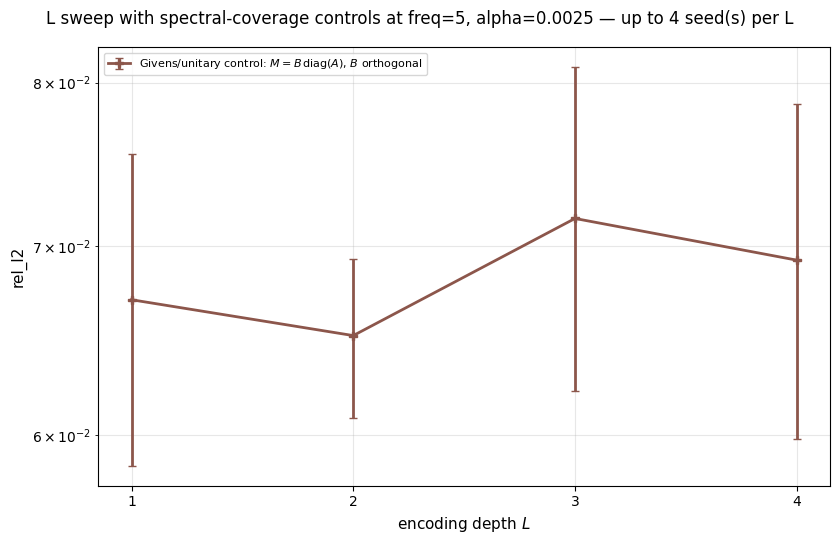

In [ ]:
# Reload -- now picks up all three arms.
L_sweep_ckpts = load_checkpoints(
    L_SWEEP_DIR, pde_type=PDE_TYPE, freq=FIXED_FREQ, **{PARAM2_NAME: FIXED_ALPHA_OR_C}, model_type="fourier_unitary",
)
print(f"{len(L_sweep_ckpts)} checkpoints loaded")

fig = plot_L_sweep_with_ff(
    L_sweep_ckpts, metric="rel_l2", target_frequency=2 * FIXED_FREQ,
    save_path=ROOT / "figures" / "checkpoint_pipeline" / "L_sweep_with_ff.png",
)

In [9]:
from checkpoints import transplant_diagnostic

qckpt = load_checkpoints(
    L_SWEEP_DIR, model_type="quantum", L=1,
    freq=FIXED_FREQ, **{PARAM2_NAME: FIXED_ALPHA_OR_C},
)[0]
info = transplant_diagnostic(qckpt)

[transplant] F=4 N=3 D=35 grid=256 amplitude reconstruction rel. error=3.57e-07 OK
[transplant] max relative |u| discrepancy over 512 points: 3.14e-06 OK
[transplant] quantum rel_l2   = 1.157064e-01 (310 params)
[transplant] transplant rel_l2 = 1.157065e-01 (2720 params)
[transplant] => MATCH. The trained solution lies inside the free-M classical model's function class, so its failure when trained from random init is an OPTIMISATION effect, not a capacity or spectral-support one.


In [10]:
from src.models import SymmetricUnitaryHeatQPINN
from src.diagnostics import train_and_diagnose

model = SymmetricUnitaryHeatQPINN(
    feature_size=FEATURE_SIZE, hidden_feature=HIDDEN_FEATURE,
    hidden_readout=HIDDEN_READOUT_QUANTUM, n_photons_per_pass=3,
    n_encoding_layers=1, pde=L_SWEEP_PDE,
)
model.self_check()
print(sum(p.numel() for p in model.parameters() if p.requires_grad), "params")

metrics, diag, _ = train_and_diagnose(
    model=model, pde=L_SWEEP_PDE, seed=42, epochs=EPOCHS,
    device=DEVICE, model_type="fourier_symmetric",
    track_best=TRACK_BEST, eval_every=EVAL_EVERY,
)
print(metrics["rel_l2"])

[symmetric] max |sum_n p_n - 1| = 2.98e-07 OK
320 params
Parameters — total: 320  trainable: 320

Training for 15000 epochs on cpu  (dtype=torch.float32)
Epoch     1/15000 | Loss: 2.6144e+00 | PDE: 2.85e-06 | Cons: 2.33e-01 | IC: 5.00e-01 | BC: 0.00e+00 | Time: 0.0s
Evaluating on 60×60 grid …
  Relative L2 : 1.0184e+00
  MAE         : 2.3849e-01
  Max abs err : 1.0606e+00
  RMSE        : 3.2439e-01
Evaluating on 60×60 grid …
  Relative L2 : 1.0001e+00
  MAE         : 2.3397e-01
  Max abs err : 1.0003e+00
  RMSE        : 3.1855e-01
Evaluating on 60×60 grid …
  Relative L2 : 1.0000e+00
  MAE         : 2.3397e-01
  Max abs err : 9.9934e-01
  RMSE        : 3.1851e-01
Evaluating on 60×60 grid …
  Relative L2 : 1.0000e+00
  MAE         : 2.3396e-01
  Max abs err : 1.0012e+00
  RMSE        : 3.1852e-01
Evaluating on 60×60 grid …
  Relative L2 : 1.0001e+00
  MAE         : 2.3396e-01
  Max abs err : 1.0027e+00
  RMSE        : 3.1854e-01
Evaluating on 60×60 grid …
  Relative L2 : 1.0010e+00
  MA